# NICE: Non-Functional Requirements Identification, Classification, and Explanation with Small Language Models

Reproduction notebook for *Rejithkumar & Anish, "NICE: Non-Functional Requirements Identification, Classification, and Explanation Using Small Language Models"* (ICSE-SEIP 2025), using the **PROMISE (relabeled-NICE)** dataset.

**Pipeline (as described in the paper)**

1. Load the multi-label relabeled PROMISE dataset (Zenodo DOI `10.5281/zenodo.14590935`, CC-BY-4.0).
2. Generate natural-language **explanations** for each requirement's labels with a large model (the paper used GPT-4o; this version uses a **Gemini** model instead).
3. **Fine-tune small language models** (T5, Llama 3.1, Phi 3) on `requirement -> labels + explanation`.
4. Evaluate **identification** (FR vs NFR), multi-label **classification** (12 NFR classes) with precision / recall / F1, and the **explanations** (ROUGE here; the paper additionally used human evaluation and a survey of 20 practitioners).

**Honest caveats about this reproduction**

- The exact hyperparameters, train/test split and prompt wording from the paper were *not* available when this notebook was written, so the values below are sensible defaults you can change in the config cell. Numbers will not match the paper exactly.
- Step 2 uses a Gemini model (not GPT-4o as in the paper), so the explanation targets will differ in style from the paper's. It needs a `GEMINI_API_KEY` (free key from Google AI Studio). Without it the notebook falls back to a simple template explanation, which is **not** what the paper did and will make the explanation part of the results less meaningful.
- Fine-tuning Llama 3.1 8B / Phi 3 needs a GPU (Colab T4 with 4-bit QLoRA works but is slow; A100/L4 recommended). Llama 3.1 is a gated model on Hugging Face. T5 runs on a modest GPU and is enabled by default.

Dataset citation: Rejithkumar, G. & Anish, P.R. (2025). *[Dataset] NICE...* Zenodo. https://doi.org/10.5281/zenodo.14590935. Based on PROMISE (Cleland-Huang et al., 2007) and its augmentation by Dalpiaz et al. (RE 2019).

## 1. Setup

In [ ]:
!pip -q install "transformers>=4.44" "datasets" "peft>=0.12" "accelerate>=0.33" "bitsandbytes" "sentencepiece" "scikit-learn" "rouge_score" "google-genai" "pandas" "matplotlib" "tqdm"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, re, json, random, hashlib, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

# ------------------------------------------------------------------ CONFIG
SEED = 42
TEST_SIZE = 0.2                      # paper split not retrieved -> 80/20 holdout (change if you know theirs)
WORK_DIR = "nice_work"
os.makedirs(WORK_DIR, exist_ok=True)

DATA_URL = "https://zenodo.org/records/14590935/files/PROMISE-relabeled-NICE.csv?download=1"
DATA_MD5 = "977399184e55483b3c971b7094a53279"   # from the Zenodo record
DATA_PATH = os.path.join(WORK_DIR, "PROMISE-relabeled-NICE.csv")

# Which models to fine-tune. T5 is cheap; the causal LMs need a big GPU.
RUN_T5, RUN_PHI3, RUN_LLAMA31 = True, False, False
T5_NAME    = "google/flan-t5-base"                   # swap for "t5-base"/"t5-large" to be closer to plain T5
PHI3_NAME  = "microsoft/Phi-3-mini-4k-instruct"
LLAMA_NAME = "meta-llama/Llama-3.1-8B-Instruct"       # gated: accept the license + `huggingface-cli login`

# Training defaults (assumptions, not taken from the paper)
T5_EPOCHS, T5_LR, T5_BS = 10, 3e-4, 8
LLM_EPOCHS, LLM_LR, LLM_BS, LLM_GRAD_ACC = 3, 2e-4, 2, 8
MAX_IN_LEN, MAX_OUT_LEN = 192, 160

# Explanation generation with a large model (paper: GPT-4o; here: Gemini)
USE_GEMINI = True                                     # needs GEMINI_API_KEY; falls back to templates otherwise
GEMINI_MODEL = "gemini-3.8-flash"                     # model name from Google's current quickstart; change if your key lacks access
LIMIT = None                                          # set e.g. 60 for a quick smoke test on a subset

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU only)")

GPU: Tesla T4


## 2. Load the PROMISE (relabeled-NICE) dataset

The CSV has 16 columns: `ProjectID`, `RequirementText`, `IsFunctional`, `IsQuality`, then 12 binary NFR classes:
Availability (A), Fault Tolerance (FT), Legal (L), Look & Feel (LF), Maintainability (MN), Operability (O), Performance (PE), Portability (PO), Scalability (SC), Security (SE), Usability (US), Other (OT).

If the automatic download fails (some networks block Zenodo), download the file manually and upload it to `nice_work/PROMISE-relabeled-NICE.csv`.

In [ ]:
def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# Zenodo often returns 403 to scripted downloads from Colab. Try a few URLs, then fall back to a manual upload.
CANDIDATE_URLS = [
    "https://zenodo.org/api/records/14590935/files/PROMISE-relabeled-NICE.csv/content",
    "https://zenodo.org/records/14590935/files/PROMISE-relabeled-NICE.csv?download=1",
    "https://zenodo.org/record/14590935/files/PROMISE-relabeled-NICE.csv",
]
HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                         "(KHTML, like Gecko) Chrome/120.0 Safari/537.36",
           "Accept": "text/csv,application/octet-stream,*/*"}

def try_download():
    for url in CANDIDATE_URLS:
        try:
            req = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(req, timeout=60) as r:
                data = r.read()
            if len(data) > 1000 and b"<html" not in data[:500].lower():
                with open(DATA_PATH, "wb") as f:
                    f.write(data)
                print("Downloaded from", url)
                return True
            print("Got an unexpected response from", url)
        except Exception as e:
            print(f"  {url} -> {e}")
    return False

def try_colab_upload():
    try:
        from google.colab import files
    except ImportError:
        return False
    print("\nAutomatic download failed. Download PROMISE-relabeled-NICE.csv in your browser from")
    print("  https://zenodo.org/records/14590935  then choose it in the upload box below.")
    up = files.upload()
    if not up:
        return False
    name = next(iter(up))
    with open(DATA_PATH, "wb") as f:
        f.write(up[name])
    print("Saved upload as", DATA_PATH)
    return True

if not os.path.exists(DATA_PATH) or os.path.getsize(DATA_PATH) == 0:
    if not (try_download() or try_colab_upload()):
        raise FileNotFoundError(
            "Could not get the dataset. Download PROMISE-relabeled-NICE.csv from "
            f"https://zenodo.org/records/14590935 and put it at {DATA_PATH}, then re-run this cell.")

if md5(DATA_PATH) == DATA_MD5:
    print("md5 matches Zenodo record: True")
else:
    print("NOTE: md5 differs from the Zenodo record. This usually means the CSV was opened and re-saved "
          "(e.g. in Excel), which changes encoding/line endings but not the data. Check the shape and "
          "columns printed below (expect 16 columns); if they look wrong, re-download the original file.")

# The file contains Windows-1252 characters (e.g. curly apostrophes), so try several encodings.
raw = None
for enc in ("utf-8", "utf-8-sig", "cp1252", "latin-1"):
    try:
        raw = pd.read_csv(DATA_PATH, encoding=enc)
        print("Read CSV with encoding:", enc)
        break
    except UnicodeDecodeError:
        continue
# Tidy common mis-encoded punctuation so explanations/prompts get clean text
for c in raw.select_dtypes(include="object").columns:
    raw[c] = (raw[c].str.replace("\u2019", "'").str.replace("\u2018", "'")
              .str.replace("\u201c", '"').str.replace("\u201d", '"').str.replace("\u2013", "-")
              .str.replace("\u00a0", " "))
print(raw.shape)
print(list(raw.columns))
raw.head(3)

  https://zenodo.org/api/records/14590935/files/PROMISE-relabeled-NICE.csv/content -> HTTP Error 403: Forbidden
  https://zenodo.org/records/14590935/files/PROMISE-relabeled-NICE.csv?download=1 -> HTTP Error 403: Forbidden
  https://zenodo.org/record/14590935/files/PROMISE-relabeled-NICE.csv -> HTTP Error 403: Forbidden

Automatic download failed. Download PROMISE-relabeled-NICE.csv in your browser from
  https://zenodo.org/records/14590935  then choose it in the upload box below.


Saving PROMISE-relabeled-NICE.csv to PROMISE-relabeled-NICE.csv
Saved upload as nice_work/PROMISE-relabeled-NICE.csv
md5 matches Zenodo record: True
Read CSV with encoding: utf-8
(622, 16)
['ProjectID', 'RequirementText', 'IsFunctional', 'IsQuality', 'Availability (A)', 'Fault Tolerance (FT)', 'Legal (L)', 'Look & Feel (LF)', 'Maintainability (MN)', 'Operability (O)', 'Performance (PE)', 'Portability (PO)', 'Scalability (SC)', 'Security (SE)', 'Usability (US)', 'Other (OT)']


,ProjectID,RequirementText,IsFunctional,IsQuality,Availability (A),Fault Tolerance (FT),Legal (L),Look & Feel (LF),Maintainability (MN),Operability (O),Performance (PE),Portability (PO),Scalability (SC),Security (SE),Usability (US),Other (OT)
0,1,'The system shall refresh the display every 60...,1,1,0,0,0,0,0,0,1,0,0,0,0,0
1,1,'The application shall match the color of the ...,0,1,0,0,1,1,0,0,0,0,0,0,0,0
2,1,'If projected the data must be readable. On a ...,0,1,0,0,0,1,0,0,0,0,0,0,1,0


In [ ]:
# Map whatever the CSV headers are called onto canonical names (robust to "Availability (A)" vs "A" vs "Availability").
NFR_CLASSES = [("Availability","A"),("Fault Tolerance","FT"),("Legal","L"),("Look & Feel","LF"),
               ("Maintainability","MN"),("Operability","O"),("Performance","PE"),("Portability","PO"),
               ("Scalability","SC"),("Security","SE"),("Usability","US"),("Other","OT")]

def norm(s): return re.sub(r"[^a-z0-9]", "", str(s).lower())

def find_col(df, full, abbr):
    cols = {norm(c): c for c in df.columns}
    for key in (norm(f"{full} ({abbr})"), norm(full), norm(abbr)):
        if key in cols: return cols[key]
    for k, c in cols.items():                      # prefix match as a last resort
        if k.startswith(norm(full)): return c
    raise KeyError(f"Cannot find a column for {full} ({abbr}) in {list(df.columns)}")

text_col = next(c for c in raw.columns if norm(c) in ("requirementtext", "requirement", "text"))
fr_col   = next(c for c in raw.columns if norm(c) == "isfunctional")
q_col    = next(c for c in raw.columns if norm(c) == "isquality")
proj_col = next((c for c in raw.columns if norm(c) == "projectid"), None)

LABELS = [full for full, _ in NFR_CLASSES]
df = pd.DataFrame({
    "project": raw[proj_col] if proj_col else 0,
    "text": raw[text_col].astype(str).str.strip(),
    "is_functional": raw[fr_col].astype(int),
    "is_quality": raw[q_col].astype(int),
})
for full, abbr in NFR_CLASSES:
    df[full] = raw[find_col(raw, full, abbr)].fillna(0).astype(int)

df = df.drop_duplicates(subset="text").reset_index(drop=True)
if LIMIT: df = df.sample(LIMIT, random_state=SEED).reset_index(drop=True)
print("Requirements:", len(df))
print("Functional:", df.is_functional.sum(), "| Quality (NFR):", df.is_quality.sum(),
      "| both:", ((df.is_functional == 1) & (df.is_quality == 1)).sum())

Requirements: 622
Functional: 308 | Quality (NFR): 381 | both: 80


Usability          85
Security           75
Look & Feel        69
Performance        63
Operability        58
Availability       38
Maintainability    34
Legal              31
Scalability        29
Portability        22
Fault Tolerance    16
Other               0

Avg #NFR labels per quality requirement: 1.36


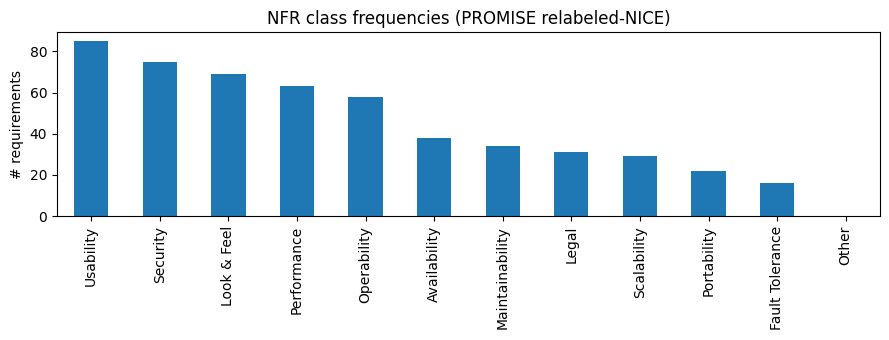

In [ ]:
counts = df[LABELS].sum().sort_values(ascending=False)
print(counts.to_string())
print("\nAvg #NFR labels per quality requirement: %.2f" %
      df.loc[df.is_quality == 1, LABELS].sum(axis=1).mean())

counts.plot.bar(figsize=(9, 3.5), title="NFR class frequencies (PROMISE relabeled-NICE)")
plt.ylabel("# requirements"); plt.tight_layout(); plt.show()

## 3. Train / test split

Stratified on the (FR, NFR) type so both identification classes appear in both splits. The paper's exact protocol is not reproduced here.

In [ ]:
strat = df.is_functional.astype(str) + df.is_quality.astype(str)
if strat.value_counts().min() < 2: strat = None
train_df, test_df = train_test_split(df, test_size=TEST_SIZE, random_state=SEED, stratify=strat)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print(len(train_df), "train /", len(test_df), "test")

497 train / 125 test


## 4. Explanation generation (Gemini)

For every requirement the Gemini model is given the requirement text and its gold labels and asked to justify them in 2-3 sentences. These become the explanation targets the small models learn to produce. Results are cached to disk so the (paid) calls run once.

The prompt below is my own wording; the paper's exact prompt was not available.

In [ ]:
EXPL_CACHE = os.path.join(WORK_DIR, "explanations.json")
explanations = json.load(open(EXPL_CACHE)) if os.path.exists(EXPL_CACHE) else {}

def gold_summary(row):
    kinds = []
    if row["is_functional"]: kinds.append("functional")
    if row["is_quality"]:    kinds.append("non-functional (quality)")
    cats = [l for l in LABELS if row[l] == 1]
    return kinds, cats

def template_explanation(row):
    """Fallback ONLY. Not what the paper did - just keeps the pipeline runnable offline."""
    kinds, cats = gold_summary(row)
    s = "This requirement is " + " and ".join(kinds) + "." if kinds else "This requirement has no clear type."
    if cats:
        s += " It addresses " + ", ".join(cats) + "."
    return s

EXPL_PROMPT = """You are a requirements engineering expert.
Requirement: "{text}"
Its type: {kinds}.
Its non-functional categories: {cats}.

In 2-3 sentences, explain why the requirement belongs to exactly these type(s) and categories.
Point to the specific words or phrases in the requirement that justify each label. Do not mention categories that are not listed."""

import time

def gemini_explanation(client, row, retries=4):
    kinds, cats = gold_summary(row)
    msg = EXPL_PROMPT.format(text=row["text"], kinds=" and ".join(kinds) or "unclear",
                             cats=", ".join(cats) or "none (purely functional)")
    cfg = genai_types.GenerateContentConfig(temperature=0.0, max_output_tokens=512)   # headroom in case the model "thinks"
    for attempt in range(retries):
        try:
            r = client.models.generate_content(model=GEMINI_MODEL, contents=msg, config=cfg)
            if r.text and r.text.strip():
                return r.text.strip()
        except Exception as e:                      # rate limits (free tier) etc.
            if attempt == retries - 1: raise
        time.sleep(2 ** attempt)
    raise RuntimeError("empty response")

client = None
GEMINI_KEY = os.environ.get("AQ.Ab8RN6KlNyIOxxyTel9TT32iBgr0OWqYeqskaIis8mdnfkrhlw") or os.environ.get("GOOGLE_API_KEY")
if USE_GEMINI and GEMINI_KEY:
    from google import genai
    from google.genai import types as genai_types
    client = genai.Client(api_key=GEMINI_KEY)
else:
    print("No GEMINI_API_KEY found (or USE_GEMINI=False) -> using TEMPLATE explanations (not paper-faithful).")
    print("In Colab: from google.colab import userdata; os.environ['GEMINI_API_KEY'] = userdata.get('GEMINI_API_KEY')")

from concurrent.futures import ThreadPoolExecutor
failed = []
def get_expl(i_row):
    i, row = i_row
    key = row["text"]
    if key in explanations: return key, explanations[key], True
    if client is None: return key, template_explanation(row), False
    try:
        return key, gemini_explanation(client, row), True
    except Exception as e:
        failed.append(str(e)[:200])
        return key, template_explanation(row), False      # fallback is NOT cached below

all_df = pd.concat([train_df, test_df], ignore_index=True)
with ThreadPoolExecutor(max_workers=4 if client else 1) as ex:
    for key, e, from_llm in tqdm(ex.map(get_expl, all_df.iterrows()), total=len(all_df)):
        if from_llm: explanations[key] = e
        else: explanations.setdefault("__fallback__" + key, e)
if client: json.dump({k: v for k, v in explanations.items() if not k.startswith("__fallback__")},
                     open(EXPL_CACHE, "w"), indent=1)
if failed:
    print(f"WARNING: {len(failed)} Gemini calls failed; template text used for those. First error: {failed[0]}")
    print("Re-run this cell to retry only the failed ones (successful ones are cached).")
for d in (train_df, test_df):                                # prefer Gemini text, else template fallback
    d["explanation"] = [explanations.get(t, explanations.get("__fallback__" + t)) for t in d["text"]]
print(train_df.loc[0, ["text", "explanation"]].to_dict())

No GEMINI_API_KEY found (or USE_GEMINI=False) -> using TEMPLATE explanations (not paper-faithful).
In Colab: from google.colab import userdata; os.environ['GEMINI_API_KEY'] = userdata.get('GEMINI_API_KEY')


  0%|          | 0/622 [00:00<?, ?it/s]

{'text': "'Once a game is initiated the product shall allow each player to position their 5 ships on their respective defensive grids.'", 'explanation': 'This requirement is functional.'}


## 5. Task format

A single sequence-to-sequence format covers all three tasks. The model reads the requirement and generates

```
functional: yes | quality: yes | categories: Performance; Security | explanation: ...
```

- **Identification** = the `functional` / `quality` fields (a requirement can be both).
- **Classification** = the `categories` field (multi-label, 12 classes; `none` for purely functional).
- **Explanation** = the free-text rationale.

In [ ]:
INSTR = "Identify whether the software requirement is functional and/or quality (non-functional), classify its NFR categories, and explain."

def make_input(text): return f"{INSTR}\nRequirement: {text}"

def make_target(row):
    cats = [l for l in LABELS if row[l] == 1]
    return (f"functional: {'yes' if row['is_functional'] else 'no'} | "
            f"quality: {'yes' if row['is_quality'] else 'no'} | "
            f"categories: {'; '.join(cats) if cats else 'none'} | "
            f"explanation: {row['explanation']}")

OUT_RE = re.compile(r"functional:\s*(yes|no)\s*\|\s*quality:\s*(yes|no)\s*\|\s*categories:\s*(.*?)\s*(?:\|\s*explanation:\s*(.*))?$",
                    re.I | re.S)
LABEL_LOOKUP = {norm(l): l for l in LABELS}

def parse_output(s):
    """Return dict(fr, q, cats(set), expl, ok). Malformed output -> all-zero prediction, ok=False."""
    m = OUT_RE.search(s.strip())
    if not m:
        return dict(fr=0, q=0, cats=set(), expl=s, ok=False)
    cats = set()
    for c in re.split(r"[;,]", m.group(3)):
        k = norm(c)
        if k in LABEL_LOOKUP: cats.add(LABEL_LOOKUP[k])
    return dict(fr=int(m.group(1).lower() == "yes"), q=int(m.group(2).lower() == "yes"),
                cats=cats, expl=(m.group(4) or "").strip(), ok=True)

train_df["src"] = train_df.text.map(make_input); train_df["tgt"] = train_df.apply(make_target, axis=1)
test_df["src"]  = test_df.text.map(make_input);  test_df["tgt"]  = test_df.apply(make_target, axis=1)
print(train_df.tgt[0])
assert parse_output(train_df.tgt[0])["ok"]

functional: yes | quality: no | categories: none | explanation: This requirement is functional.


## 6. Evaluation helpers

In [ ]:
from rouge_score import rouge_scorer
_rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def evaluate(preds_raw, test_df, name):
    parsed = [parse_output(p) for p in preds_raw]
    y_fr, y_q = test_df.is_functional.values, test_df.is_quality.values
    p_fr = np.array([p["fr"] for p in parsed]); p_q = np.array([p["q"] for p in parsed])
    Y = test_df[LABELS].values
    P = np.array([[int(l in p["cats"]) for l in LABELS] for p in parsed])

    res = {"model": name, "format_ok": float(np.mean([p["ok"] for p in parsed]))}
    for tag, y, p in (("FR", y_fr, p_fr), ("NFR", y_q, p_q)):
        pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
        res[f"ident_{tag}_F1"] = f1
    for avg in ("micro", "macro", "weighted"):
        pr, rc, f1, _ = precision_recall_fscore_support(Y, P, average=avg, zero_division=0)
        res[f"cls_{avg}_P"], res[f"cls_{avg}_R"], res[f"cls_{avg}_F1"] = pr, rc, f1
    res["cls_exact_match"] = accuracy_score(Y, P)
    rl = [_rouge.score(ref, p["expl"])["rougeL"].fmeasure for ref, p in zip(test_df.explanation, parsed)]
    res["expl_rougeL"] = float(np.mean(rl))

    per = precision_recall_fscore_support(Y, P, zero_division=0)
    per_df = pd.DataFrame({"P": per[0], "R": per[1], "F1": per[2], "support": per[3]}, index=LABELS)
    return res, per_df

# Self-test of the pipeline with the gold targets (should give F1 = 1.0 for identification/classification)
_res, _ = evaluate(test_df.tgt.tolist(), test_df, "gold-sanity-check")
print({k: round(v, 3) if isinstance(v, float) else v for k, v in _res.items()})

{'model': 'gold-sanity-check', 'format_ok': 1.0, 'ident_FR_F1': 1.0, 'ident_NFR_F1': 1.0, 'cls_micro_P': 1.0, 'cls_micro_R': 1.0, 'cls_micro_F1': 1.0, 'cls_macro_P': 0.917, 'cls_macro_R': 0.917, 'cls_macro_F1': 0.917, 'cls_weighted_P': 1.0, 'cls_weighted_R': 1.0, 'cls_weighted_F1': 1.0, 'cls_exact_match': 1.0, 'expl_rougeL': 1.0}


## 7. Fine-tune T5 (encoder-decoder)

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, Seq2SeqTrainer, Seq2SeqTrainingArguments,
                          DataCollatorForSeq2Seq)
from datasets import Dataset
import math

def generate_seq2seq(model, tok, srcs, bs=32, max_new_tokens=MAX_OUT_LEN):
    model.eval(); outs = []
    for i in tqdm(range(0, len(srcs), bs), desc="generate"):
        enc = tok(srcs[i:i+bs], return_tensors="pt", padding=True, truncation=True,
                  max_length=MAX_IN_LEN).to(model.device)
        with torch.no_grad():
            g = model.generate(**enc, max_new_tokens=max_new_tokens, num_beams=4)
        outs += tok.batch_decode(g, skip_special_tokens=True)
    return outs

results, per_class, raw_preds = [], {}, {}

if RUN_T5:
    set_seed()
    tok = AutoTokenizer.from_pretrained(T5_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(T5_NAME)

    def tok_fn(b):
        x = tok(b["src"], max_length=MAX_IN_LEN, truncation=True)
        x["labels"] = tok(text_target=b["tgt"], max_length=MAX_OUT_LEN, truncation=True)["input_ids"]
        return x
    ds = Dataset.from_pandas(train_df[["src", "tgt"]]).map(tok_fn, batched=True, remove_columns=["src", "tgt"])

    # transformers v5 removed `warmup_ratio`; compute 5% warmup as a step count instead
    t5_warmup = max(1, math.ceil(0.05 * math.ceil(len(ds) / T5_BS) * T5_EPOCHS))
    args = Seq2SeqTrainingArguments(
        output_dir=os.path.join(WORK_DIR, "t5"), num_train_epochs=T5_EPOCHS, learning_rate=T5_LR,
        per_device_train_batch_size=T5_BS, weight_decay=0.01, warmup_steps=t5_warmup,
        bf16=torch.cuda.is_available() and torch.cuda.is_bf16_supported(),   # fp16 is unstable for T5
        save_strategy="no", logging_steps=50, report_to="none", seed=SEED)
    Seq2SeqTrainer(model=model, args=args, train_dataset=ds,
                   data_collator=DataCollatorForSeq2Seq(tok, model=model)).train()

    model.to("cuda" if torch.cuda.is_available() else "cpu")
    raw_preds["T5"] = generate_seq2seq(model, tok, test_df.src.tolist())
    r, per = evaluate(raw_preds["T5"], test_df, f"T5 ({T5_NAME})")
    results.append(r); per_class["T5"] = per
    model_t5, tok_t5 = model, tok          # kept in memory for the demo in section 10
    print(pd.Series(r).round(3).to_string())

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (5 outputs left out)

Map:   0%|          | 0/497 [00:00<?, ? examples/s]

Step,Training Loss
50,1.234342
100,0.147503
150,0.101177
200,0.067518
250,0.057943
300,0.035827
350,0.033396
400,0.021767
450,0.020709
500,0.013824


generate:   0%|          | 0/4 [00:00<?, ?it/s]

model              T5 (google/flan-t5-base)
format_ok                               1.0
ident_FR_F1                        0.870968
ident_NFR_F1                       0.942675
cls_micro_P                        0.688679
cls_micro_R                        0.737374
cls_micro_F1                       0.712195
cls_macro_P                        0.579245
cls_macro_R                        0.589019
cls_macro_F1                         0.5732
cls_weighted_P                     0.699784
cls_weighted_R                     0.737374
cls_weighted_F1                    0.706369
cls_exact_match                       0.712
expl_rougeL                        0.931474


## 8. Fine-tune Phi-3 and Llama 3.1 (decoder-only, 4-bit QLoRA)

Disabled by default (`RUN_PHI3`, `RUN_LLAMA31` in the config cell). LoRA rank/alpha/dropout are my defaults, not the paper's.

In [ ]:
from transformers import BitsAndBytesConfig, Trainer, TrainingArguments
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

def finetune_causal(model_name, tag):
    set_seed()
    tok = AutoTokenizer.from_pretrained(model_name, trust_remote_code=False)
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=torch.bfloat16 if bf16 else torch.float16,
                             bnb_4bit_use_double_quant=True)
    model = AutoModelForCausalLM.from_pretrained(model_name, quantization_config=bnb, device_map="auto")
    model.config.use_cache = False
    model = prepare_model_for_kbit_training(model)
    model = get_peft_model(model, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                                              target_modules="all-linear"))
    model.print_trainable_parameters()

    prompt = lambda s: f"{s}\n### Response:\n"
    def enc(row):
        p = tok(prompt(row["src"]), add_special_tokens=True, truncation=True, max_length=MAX_IN_LEN)["input_ids"]
        t = tok(row["tgt"] + tok.eos_token, add_special_tokens=False, truncation=True, max_length=MAX_OUT_LEN)["input_ids"]
        return {"input_ids": p + t, "labels": [-100] * len(p) + t}
    ds = Dataset.from_pandas(train_df[["src", "tgt"]]).map(enc, remove_columns=["src", "tgt"])

    def collate(batch):
        m = max(len(b["input_ids"]) for b in batch)
        ids = [b["input_ids"] + [tok.pad_token_id] * (m - len(b["input_ids"])) for b in batch]
        lab = [b["labels"] + [-100] * (m - len(b["labels"])) for b in batch]
        att = [[1] * len(b["input_ids"]) + [0] * (m - len(b["input_ids"])) for b in batch]
        return {"input_ids": torch.tensor(ids), "labels": torch.tensor(lab), "attention_mask": torch.tensor(att)}

    llm_warmup = max(1, math.ceil(0.05 * math.ceil(len(ds) / (LLM_BS * LLM_GRAD_ACC)) * LLM_EPOCHS))
    args = TrainingArguments(output_dir=os.path.join(WORK_DIR, tag), num_train_epochs=LLM_EPOCHS,
                             learning_rate=LLM_LR, per_device_train_batch_size=LLM_BS,
                             gradient_accumulation_steps=LLM_GRAD_ACC, warmup_steps=llm_warmup,
                             lr_scheduler_type="cosine", bf16=bf16, fp16=not bf16,
                             optim="paged_adamw_8bit", gradient_checkpointing=True,
                             save_strategy="no", logging_steps=20, report_to="none", seed=SEED)
    Trainer(model=model, args=args, train_dataset=ds, data_collator=collate).train()

    model.config.use_cache = True; model.eval(); tok.padding_side = "left"
    srcs, outs = [prompt(s) for s in test_df.src], []
    for i in tqdm(range(0, len(srcs), 8), desc="generate"):
        b = tok(srcs[i:i+8], return_tensors="pt", padding=True, truncation=True, max_length=MAX_IN_LEN).to(model.device)
        with torch.no_grad():
            g = model.generate(**b, max_new_tokens=MAX_OUT_LEN, do_sample=False, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(g[:, b["input_ids"].shape[1]:], skip_special_tokens=True)
    del model; torch.cuda.empty_cache()
    return outs

from transformers import AutoModelForCausalLM
for flag, name, tag in ((RUN_PHI3, PHI3_NAME, "Phi3"), (RUN_LLAMA31, LLAMA_NAME, "Llama3.1")):
    if flag:
        raw_preds[tag] = finetune_causal(name, tag.lower().replace(".", ""))
        r, per = evaluate(raw_preds[tag], test_df, f"{tag} ({name})")
        results.append(r); per_class[tag] = per
        print(pd.Series(r).round(3).to_string())

## 9. Results

In [ ]:
if results:
    res_df = pd.DataFrame(results).set_index("model")
    show = ["format_ok", "ident_FR_F1", "ident_NFR_F1", "cls_micro_F1", "cls_macro_F1", "cls_weighted_F1",
            "cls_exact_match", "expl_rougeL"]
    display(res_df[show].round(3))
    res_df.to_csv(os.path.join(WORK_DIR, "results.csv"))

    for tag, per in per_class.items():
        print(f"\nPer-class results: {tag}")
        display(per.round(3))
else:
    print("No model was trained - enable RUN_T5 / RUN_PHI3 / RUN_LLAMA31 in the config cell.")

,format_ok,ident_FR_F1,ident_NFR_F1,cls_micro_F1,cls_macro_F1,cls_weighted_F1,cls_exact_match,expl_rougeL
model,,,,,,,,
T5 (google/flan-t5-base),1.0,0.871,0.943,0.712,0.573,0.706,0.712,0.931



Per-class results: T5


,P,R,F1,support
Availability,1.000,0.833,0.909,6
Fault Tolerance,0.000,0.000,0.000,2
Legal,0.750,0.600,0.667,5
Look & Feel,0.643,1.000,0.783,9
Maintainability,0.455,0.556,0.500,9
Operability,0.700,0.700,0.700,10
Performance,0.583,0.636,0.609,11
Portability,0.500,0.500,0.500,4
Scalability,0.800,0.444,0.571,9
Security,0.909,0.952,0.930,21


**Reading the numbers.** The paper reports T5 reaching an average F1 of about 0.90 on multi-label NFR classification (on the industrial dataset; the PROMISE results are in the paper). Which F1 average the paper uses is not pinned down here, so this notebook reports micro, macro and weighted. `expl_rougeL` is only a proxy for explanation quality, because the paper judged explanations by humans.

## 10. Try it on your own requirement

In [ ]:
def nice_predict(text):
    """Runs the fine-tuned T5 from section 7 (requires RUN_T5=True in this session)."""
    out = generate_seq2seq(model_t5, tok_t5, [make_input(text)], bs=1)[0]
    return parse_output(out)

if RUN_T5:
    for t in ["The system shall respond to any search query within 2 seconds.",
              "Only authenticated users shall be able to export patient records.",
              "The user shall be able to add a product to the shopping cart."]:
        p = nice_predict(t)
        print(t, "\n  functional:", bool(p["fr"]), "| quality:", bool(p["q"]),
              "| categories:", sorted(p["cats"]) or "none", "\n  why:", p["expl"], "\n")

generate:   0%|          | 0/1 [00:00<?, ?it/s]

The system shall respond to any search query within 2 seconds. 
  functional: False | quality: True | categories: ['Performance'] 
  why: This requirement is non-functional (quality). It addresses Performance. 



generate:   0%|          | 0/1 [00:00<?, ?it/s]

Only authenticated users shall be able to export patient records. 
  functional: False | quality: True | categories: ['Security'] 
  why: This requirement is non-functional (quality). It addresses Security. 



generate:   0%|          | 0/1 [00:00<?, ?it/s]

The user shall be able to add a product to the shopping cart. 
  functional: True | quality: False | categories: none 
  why: This requirement is functional. 



## References

- Rejithkumar, G., Anish, P.R. *NICE: Non-Functional Requirements Identification, Classification, and Explanation Using Small Language Models.* ICSE-SEIP 2025. Pre-print: https://zenodo.org/records/14709254
- Dataset: https://doi.org/10.5281/zenodo.14590935 (CC-BY-4.0)
- Cleland-Huang et al. (2007), *Automated classification of non-functional requirements*; Dalpiaz et al. (2019), *Requirements classification with interpretable machine learning and dependency parsing*.